<a href="https://colab.research.google.com/github/RoihansLab/Machine-Learning-Projects/blob/main/PraktikumM3_Linear_Logistik_Latihan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [59]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,

)
import matplotlib.pyplot as plt


In [60]:
X, y = load_breast_cancer(return_X_y=True)

print("jumlah seluruh sampel:", X.shape[0])
print("jumlah fitur:", X.shape[1])
print("jumlah sample kelas 0 (malignant):", (y == 0).sum())
print("jumlah sampel kelas 1 (benign):", (y == 1).sum())

jumlah seluruh sampel: 569
jumlah fitur: 30
jumlah sample kelas 0 (malignant): 212
jumlah sampel kelas 1 (benign): 357


In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=24, stratify=y)

print('Jumlah data training:', X_train.shape)
print('jumlah data testing:', X_test.shape)

Jumlah data training: (455, 30)
jumlah data testing: (114, 30)


In [62]:
clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=50, random_state=42)
)

In [63]:
clf.fit(X_train, y_train)
print("\nmodel berhasil di latih")


model berhasil di latih


In [64]:
y_pred = clf.predict(X_test)
y_prob = clf.predict_proba(X_test)

print("\ncontoh prediksi lima sample pertama:")
print("label aktual :", y_test[:5])
print("label prediksi:", y_pred[:5])
print("pobabilitas [0, 1]:")
print(y_prob[:5, :])


contoh prediksi lima sample pertama:
label aktual : [0 1 1 0 1]
label prediksi: [1 1 1 0 1]
pobabilitas [0, 1]:
[[2.99764314e-01 7.00235686e-01]
 [2.83934751e-04 9.99716065e-01]
 [8.72019233e-03 9.91279808e-01]
 [9.99990610e-01 9.38966772e-06]
 [1.09349916e-04 9.99890650e-01]]


In [65]:
# Accuracy: proporsi seluruh prediksi yang benar.
accuracy = accuracy_score(y_test, y_pred)
# Precision untuk kelas 1 (benign): Dari semua prediksi benign, berapa yang benar-benar benign?
precision = precision_score(y_test, y_pred, pos_label=1)
# Recall untuk kelas 1 (benign): Dari semua sampel benign yang sebenarnya, berapa yang terdeteksi?
recall = recall_score(y_test, y_pred, pos_label=1)
# f1-score untuk kelas 1: Rata-rata harmonik antara precision dan recall.
f1 = f1_score(y_test, y_pred)
# Recall khusus kelas 0 (malignant): Dari semua tumor ganas yang sebenarnya, berapa yang terdeteksi?
maglinant_recall = recall_score(
    y_test, y_pred, pos_label=0
)
# ROC AUC: Mengukur kemampuan model secara keseluruhan dalam membedakan antara kelas 0 (malignant) dan kelas 1 (benign). Semakin mendekati 1, semakin baik.
roc_auc = roc_auc_score(y_test, y_prob[:, 1])

In [66]:
print("\n======================Hasil Evaluasi Model==============")
print(f'Accuracy {accuracy * 100:.2f}%')
print(f'Precision {precision:.4f}')
print(f'Recall (benign) {recall:.4f}')
print(f'F1-Score {f1:.4f}')
print(f'Recall (Maglinant) {maglinant_recall:.4f}')
print(f'ROC AUC {roc_auc:.4f}')


======================Hasil Evaluasi Model==============
Accuracy 97.37%
Precision 0.9600
Recall (benign) 1.0000
F1-Score 0.9796
Recall (Maglinant) 0.9286
ROC AUC 0.9884


In [67]:
data = load_breast_cancer()
print("\n==============Classification Report===========")
print(
    classification_report(
        y_test, y_pred, labels=[0, 1],
        target_names=["Maglinant (ganas)", "Benign (jinak)"],
        zero_division=0,
    )
)


==============Classification Report===========
                   precision    recall  f1-score   support

Maglinant (ganas)       1.00      0.93      0.96        42
   Benign (jinak)       0.96      1.00      0.98        72

         accuracy                           0.97       114
        macro avg       0.98      0.96      0.97       114
     weighted avg       0.97      0.97      0.97       114




===================Confusion Matrix===================
[[39  3]
 [ 0 72]]


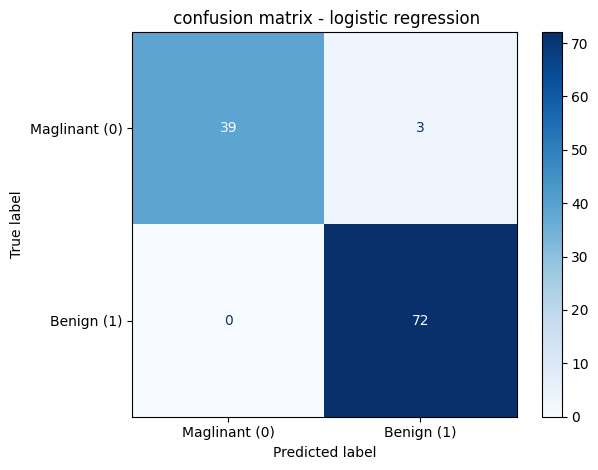

In [68]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("\n===================Confusion Matrix===================")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Maglinant (0)", "Benign (1)"],
)
disp.plot(cmap="Blues", values_format="d")
plt.title(" confusion matrix - logistic regression")
plt.tight_layout()
plt.show()